In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
import matplotlib.pyplot as plt


In [14]:
data = pd.read_csv('DATA/sessions_complete.csv')

#drop future races (all values are 0)
before = len(data)
data = data[pd.to_datetime(data["date_end"], utc=True) <= pd.Timestamp.now(tz="UTC")]
print(f"Dropped {before - len(data)} future sessions; {len(data)} remain")

data.head()

Dropped 139 future sessions; 480 remain


,session_key,session_type,session_name,date_start,date_end,meeting_key,circuit_key,circuit_short_name,country_key,country_code,...,wind_speed,pressure,track_temperature,wind_direction,yellow_flag_count,circuit,lap_length_km,laps,total_track_length_km,track_type
0,9222,Practice,Day 1,2023-02-23T07:00:00+00:00,2023-02-23T16:30:00+00:00,1140,63,Sakhir,36,BRN,...,2.112881,1009.655254,35.970169,205.498305,9.0,Bahrain International Circuit,5.412,57.0,308.484,Race
1,7763,Practice,Day 2,2023-02-24T07:00:00+00:00,2023-02-24T16:30:00+00:00,1140,63,Sakhir,36,BRN,...,2.091695,1009.909661,36.444915,215.825424,2.0,Bahrain International Circuit,5.412,57.0,308.484,Race
2,7764,Practice,Day 3,2023-02-25T07:00:00+00:00,2023-02-25T16:30:00+00:00,1140,63,Sakhir,36,BRN,...,1.154217,1013.120654,36.384682,242.635112,0.0,Bahrain International Circuit,5.412,57.0,308.484,Race
3,7765,Practice,Practice 1,2023-03-03T11:30:00+00:00,2023-03-03T12:30:00+00:00,1141,63,Sakhir,36,BRN,...,2.579762,1017.314286,40.482143,300.095238,2.0,Bahrain International Circuit,5.412,57.0,308.484,Race
4,7766,Practice,Practice 2,2023-03-03T15:00:00+00:00,2023-03-03T16:00:00+00:00,1141,63,Sakhir,36,BRN,...,1.082353,1018.512941,26.972941,244.058824,1.0,Bahrain International Circuit,5.412,57.0,308.484,Race


In [15]:
X = data.drop('yellow_flag_count', axis=1)  # Replace 'target_column' with the actual target column name
y = data['yellow_flag_count']  # Replace 'target_column' with the actual target column name

<Axes: >

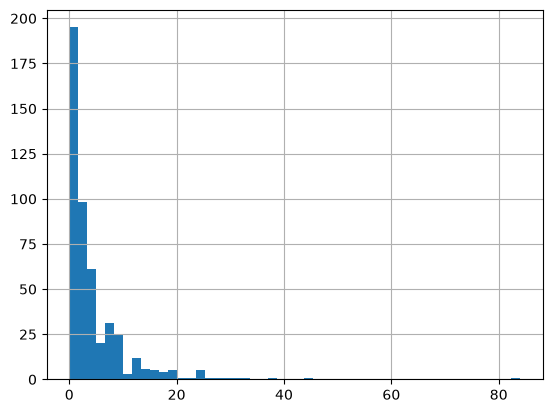

In [16]:
# View yellow flag count distribution

y.hist(bins=50)

In [17]:
# get all the session type names 
session_type_counts = data['session_type'].value_counts()

session_type_counts

session_type
Practice      246
Qualifying    117
Race          117
Name: count, dtype: int64

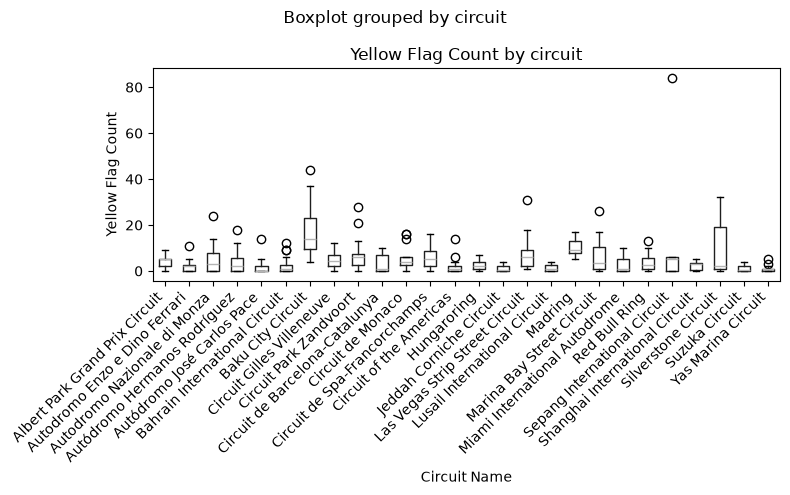

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
data.boxplot(column='yellow_flag_count', by='circuit', ax=ax, grid=False)
ax.set_title('Yellow Flag Count by circuit')
ax.set_xlabel('Circuit Name')
ax.set_ylabel('Yellow Flag Count')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
plt.tight_layout()

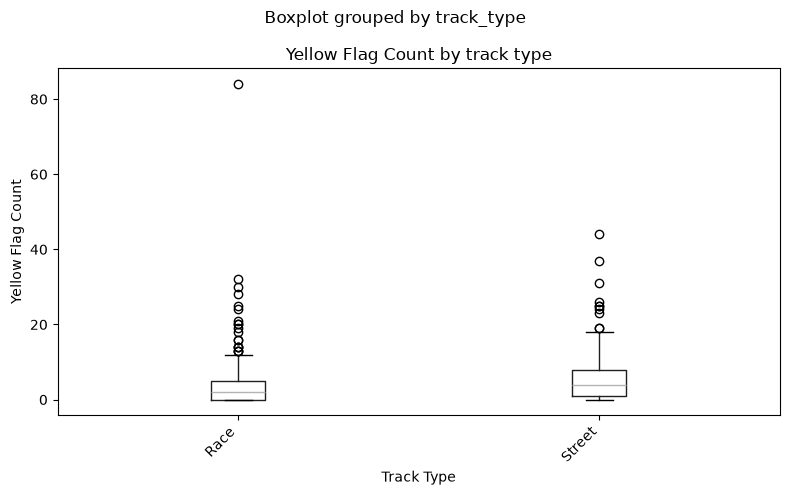

In [19]:
fig, ax = plt.subplots(figsize=(8, 5))
data.boxplot(column='yellow_flag_count', by='track_type', ax=ax, grid=False)
ax.set_title('Yellow Flag Count by track type')
ax.set_xlabel('Track Type')
ax.set_ylabel('Yellow Flag Count')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
plt.tight_layout()

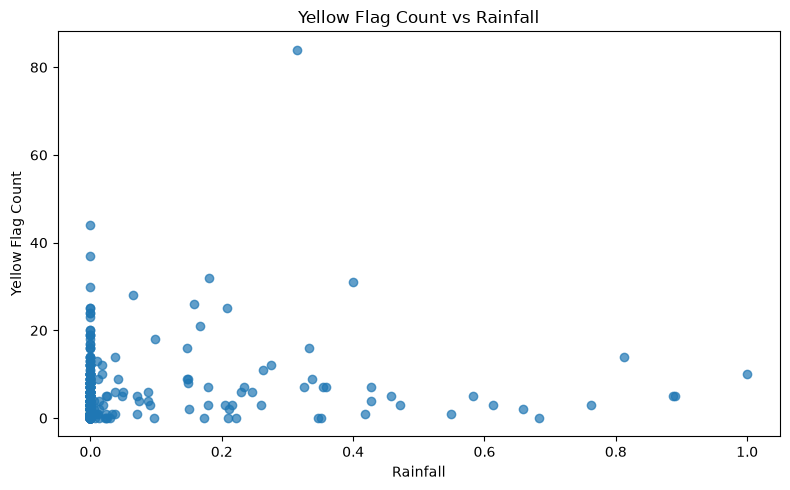

In [20]:
# view flag counts vs rainfall in scatterplot
plot_df = data[['rainfall', 'yellow_flag_count']].dropna()
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(plot_df['rainfall'], plot_df['yellow_flag_count'], alpha=0.7)
ax.set_title('Yellow Flag Count vs Rainfall')
ax.set_xlabel('Rainfall')
ax.set_ylabel('Yellow Flag Count')
plt.tight_layout()

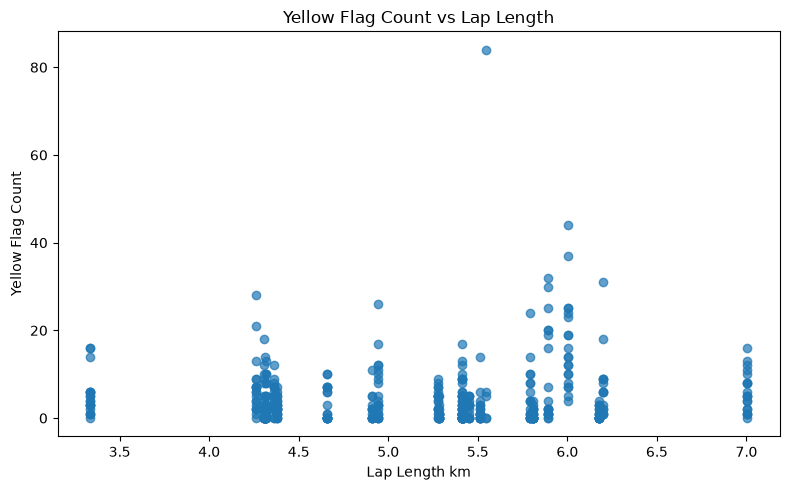

In [21]:
plot_df = data[['lap_length_km', 'yellow_flag_count']].dropna()
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(plot_df['lap_length_km'], plot_df['yellow_flag_count'], alpha=0.7)
ax.set_title('Yellow Flag Count vs Lap Length')
ax.set_xlabel('Lap Length km')
ax.set_ylabel('Yellow Flag Count')
plt.tight_layout()

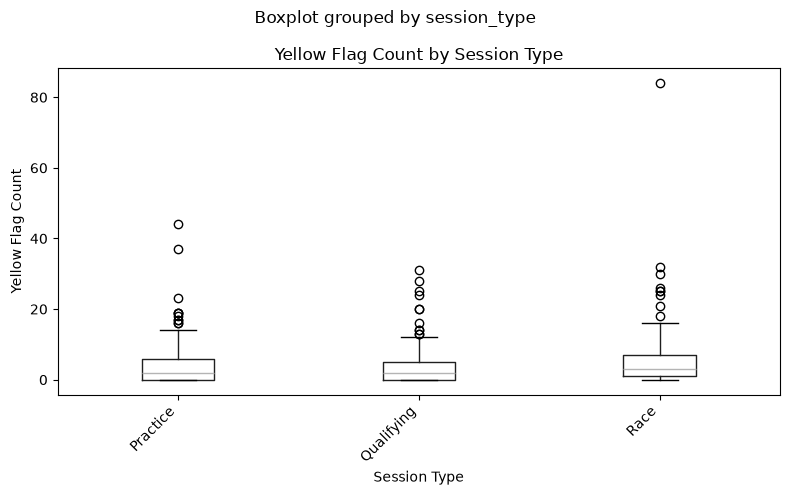

In [22]:
# view yellow flag count boxplot for each session type
fig, ax = plt.subplots(figsize=(8, 5))
data.boxplot(column='yellow_flag_count', by='session_type', ax=ax, grid=False)
ax.set_title('Yellow Flag Count by Session Type')
ax.set_xlabel('Session Type')
ax.set_ylabel('Yellow Flag Count')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
plt.tight_layout()

In [23]:
numeric_features = [
    "rainfall",
    "air_temperature",
    "humidity",
    "wind_speed",
    "pressure",
    "track_temperature",
    "wind_direction",
    "lap_length_km",
    "laps",
    "total_track_length_km",
]
categorical_features = ["circuit_short_name", "session_type", "track_type"]

X = data[numeric_features + categorical_features]
y = data["yellow_flag_count"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

In [24]:
preprocess = ColumnTransformer(
    [("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)],
    remainder="passthrough",
)

def evaluate(name, model):
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    rmse = mean_squared_error(y_test, preds) ** 0.5
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)
    print(f"{name:15s}  RMSE={rmse:.3f}  MAE={mae:.3f}  R2={r2:.3f}")
    return model


# Baseline: always predict the training-set mean.
evaluate("mean baseline", DummyRegressor(strategy="mean"))



mean baseline    RMSE=8.905  MAE=4.398  R2=-0.009


,"strategy strategy: {""mean"", ""median"", ""quantile"", ""constant""}, default=""mean""Strategy to use to generate predictions.* ""mean"": always predicts the mean of the training set* ""median"": always predicts the median of the training set* ""quantile"": always predicts a specified quantile of the training set, provided with the quantile parameter.* ""constant"": always predicts a constant value that is provided by the user.",'mean'
,"constant constant: int or float or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
,"quantile quantile: float in [0.0, 1.0], default=NoneThe quantile to predict using the ""quantile"" strategy. A quantile of0.5 corresponds to the median, while 0.0 to the minimum and 1.0 to themaximum.",None
Name,Type,Value
"constant_ constant_: ndarray of shape (1, n_outputs)Mean or median or quantile of the training targets or constant valuegiven by the user.","ndarray[float64](1, 1)",[[4.3]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](13,)","['rainfall','air_temperature','humidity',...,'circuit_short_name', 'session_type','track_type']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,13
n_outputs_ n_outputs_: intNumber of outputs.,int,1


In [25]:
# Random forest on the cleaned dataset.
rf = Pipeline(
    [
        ("prep", preprocess),
        ("model", RandomForestRegressor(n_estimators=300, random_state=42)),
    ]
)
evaluate("random forest", rf)

# Feature importances, so the README can say what the model relies on.
names = rf.named_steps["prep"].get_feature_names_out()
importances = rf.named_steps["model"].feature_importances_
print("\nTop features:")
for name, imp in sorted(zip(names, importances), key=lambda t: -t[1])[:8]:
    print(f"  {name:30s} {imp:.3f}")

print(f"\ntrain rows={len(X_train)}  test rows={len(X_test)}")

random forest    RMSE=8.430  MAE=3.859  R2=0.096

Top features:
  cat__circuit_short_name_Baku   0.242
  remainder__pressure            0.109
  remainder__track_temperature   0.096
  remainder__wind_direction      0.094
  remainder__rainfall            0.090
  remainder__humidity            0.068
  remainder__air_temperature     0.065
  remainder__wind_speed          0.063

train rows=360  test rows=120
